# Redes Neuronales V — Parte 1
### Dataset facial y preprocesamiento: detección, alineación y recorte de rostros

---

**Universidad de Cundinamarca**

**CADI:** Deep Learning — Conceptos

**Estudiante:** Ruby Dayana Cárdenas Gómez

**Docente:** Nidia Stella García Roa

**Repositorio GitHub:** `https://github.com/RubyDayana/redes-neuronales-v.git`

---

### ¿Qué se hace en este notebook?

Esta es la primera de tres partes del taller de **reconocimiento facial con redes neuronales siamesas**.
Antes de entrenar cualquier red hay que construir un dataset de rostros *limpio y organizado*, porque una red siamesa
compara **caras**, no fotos completas: si el modelo recibe el fondo, la ropa o una cara torcida, aprende a
comparar eso y no la identidad.

**Parte 1 (este notebook):** construir el dataset y preprocesar las imágenes.
**Parte 2:** red siamesa con **PyTorch** y *Triplet Loss*, con pruebas de verificación, identificación y
*one-shot*, *few-shot* y *zero-shot*.
**Parte 3:** la misma red en **TensorFlow + Keras** y comparación entre las dos implementaciones.

Lo que se hace aquí, en orden:

1. Describir y **auditar** las fotos originales (cuántas hay por persona, tamaños, fechas).
2. **Detectar** el rostro con MTCNN, ver qué hace el detector y decidir qué fotos se descartan.
3. **Alinear** (enderezar) el rostro usando la posición de los ojos y **recortar** con un margen.
4. Medir la **calidad** de cada recorte (tamaño del rostro, nitidez, brillo).
5. Guardar el dataset final organizado en carpetas, una por persona, con su archivo de metadatos.

### Consentimiento y privacidad

Las fotografías pertenecen a tres personas: la propietaria del trabajo y personas cercanas que, según declara la
estudiante, autorizaron el uso de sus imágenes **únicamente para fines académicos** de esta actividad. Por privacidad,
las carpetas se nombran con un **apodo**, las fotos originales (que además traen metadatos de ubicación) **no se
publican** en el repositorio, y los recortes solo se usan para este taller.

### Glosario rápido

| Término | Qué significa aquí |
|---|---|
| **Detección de rostros** | Encontrar en qué parte de la foto hay una cara (un recuadro) y sus puntos de referencia (ojos, nariz, boca). |
| **MTCNN** | Red neuronal en cascada de tres etapas (P-Net, R-Net, O-Net) que detecta rostros y 5 puntos de referencia (Zhang et al., 2016). |
| **Alineación** | Rotar la imagen para que la línea de los ojos quede horizontal, de modo que todas las caras tengan la misma orientación. |
| **Embedding** | Vector de números que representa una cara; la red siamesa lo aprende (Partes 2 y 3). |
| **Identidad** | Cada persona distinta del dataset; es la "etiqueta" que se usa para formar pares y tripletas. |

---
## 1. Las fotos originales

Las fotos están en `datos/fotos/<persona>/`. Son fotos personales tomadas con celulares distintos entre 2016 y 2026,
algunas recibidas por WhatsApp (por eso varias son de muy baja resolución). Esa variedad es buena para probar el
modelo, pero también lo hace más difícil.

In [1]:
import os, sys, glob, subprocess, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
SEMILLA = 42

# MTCNN viene en el paquete facenet-pytorch (sus pesos están incluidos en el paquete, no se descargan aparte).
# En Colab se instala sin dependencias para no cambiar la versión de PyTorch.
try:
    from facenet_pytorch import MTCNN
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "facenet-pytorch", "tqdm"], check=True)
    from facenet_pytorch import MTCNN

CARPETA_FOTOS = "datos/fotos"      # fotos originales (no se publican en el repositorio)
CARPETA_ROSTROS = "datos/rostros"  # recortes finales, una carpeta por persona
TAM = 112                          # lado del recorte final, en píxeles
MARGEN = 0.30                      # margen alrededor del recuadro del detector (30 %)
PROB_MIN = 0.90                    # confianza mínima del detector
LADO_MIN = 40                      # lado mínimo del rostro detectado (px) para aceptar la foto

# Fotos en las que no se puede asegurar que el rostro detectado sea la persona de la carpeta (fotos de grupo, o una
# captura de pantalla donde aparece otra persona). Se excluyen a propósito para no mezclar identidades.
EXCLUIR = {
    "gaby/20260101_152019.jpg": "foto de grupo con 3 personas de tamaño parecido",
    "gaby/20260501_151237.jpg": "foto de grupo con 3 personas de tamaño parecido",
    "yeyo/Screenshot_20221031-220205_WhatsApp.jpg": "captura de pantalla cuyo rostro principal es de otra persona (se vio al revisar los recortes)",
}

filas = []
for ruta in sorted(glob.glob(f"{CARPETA_FOTOS}/*/*")):
    if not ruta.lower().endswith((".jpg", ".jpeg", ".png")):
        continue
    persona, nombre = ruta.split("/")[-2], os.path.basename(ruta)
    with Image.open(ruta) as im:
        w, h = ImageOps.exif_transpose(im).size
    filas.append({"persona": persona, "archivo": nombre, "ancho": w, "alto": h, "megapixeles": w * h / 1e6})
fotos = pd.DataFrame(filas)

print(f"Fotos originales: {len(fotos)}   Personas: {fotos.persona.nunique()}")
print()
print(fotos.groupby("persona").agg(fotos=("archivo", "count"),
                                   ancho_mediano=("ancho", "median"), alto_mediano=("alto", "median"),
                                   mp_min=("megapixeles", "min"), mp_max=("megapixeles", "max")).round(2).to_string())

Fotos originales: 42   Personas: 3

         fotos  ancho_mediano  alto_mediano  mp_min  mp_max
persona                                                    
ayis        17         1052.0        2043.0    0.04   12.00
gaby         9          960.0        1280.0    0.04    8.32
yeyo        16         1624.0        2164.0    0.03    3.51


**Lectura.** Hay **42 fotos de 3 personas** (ayis 17, gaby 9 y yeyo 16). El desbalance es importante para el entrenamiento: gaby tiene casi la
mitad de fotos que las otras dos. El tamaño de las fotos varía enormemente, de 0.03 a 12 megapíxeles: algunas son fotos nuevas de celular y otras son
miniaturas de baja resolución, tomadas entre 2016 y 2026, lo que agrega variación natural de edad, peinado y calidad. Esa variación es útil para probar al modelo, pero
también lo hace más difícil con tan pocos ejemplos.

## 2. Detección del rostro con MTCNN

**MTCNN** (Multi-task Cascaded Convolutional Networks) procesa la imagen en tres etapas: una red pequeña propone
posibles caras, una segunda descarta falsos positivos y una tercera afina el recuadro y marca cinco puntos: ojo
izquierdo, ojo derecho, nariz y las dos comisuras de la boca. Para cada foto devuelve un recuadro, una
**confianza** (entre 0 y 1) y esos cinco puntos.

Reglas que se aplican:

- Si hay **varias caras** en la foto, se toma la de **mayor área** (en una selfie o un retrato es la persona
  principal). Las fotos de grupo donde eso no es seguro se excluyeron arriba.
- Se exige confianza ≥ 0.90 y que el rostro mida al menos 40 píxeles de lado.

In [2]:
detector = MTCNN(keep_all=True, device="cpu", post_process=False)

def cargar(ruta, lado_max=1280):
    """Abre la foto respetando la orientación del celular (EXIF) y la reduce si es muy grande."""
    im = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
    im.thumbnail((lado_max, lado_max))
    return im

def detectar(im):
    """Devuelve la mejor cara de la imagen: (recuadro, confianza, 5 puntos, número de caras vistas)."""
    cajas, probs, puntos = detector.detect(im, landmarks=True)
    if cajas is None:
        return None
    areas = [(b[2] - b[0]) * (b[3] - b[1]) for b in cajas]
    i = int(np.argmax(areas))
    return cajas[i], float(probs[i]), puntos[i], len(cajas)

detecciones = {}
for _, f in fotos.iterrows():
    clave = f"{f.persona}/{f.archivo}"
    im = cargar(f"{CARPETA_FOTOS}/{clave}")
    detecciones[clave] = (im, detectar(im))

resumen = []
for clave, (im, d) in detecciones.items():
    if d is None:
        resumen.append({"foto": clave, "caras": 0, "confianza": np.nan, "lado_rostro": np.nan})
    else:
        caja, p, _, n = d
        resumen.append({"foto": clave, "caras": n, "confianza": p, "lado_rostro": min(caja[2] - caja[0], caja[3] - caja[1])})
resumen = pd.DataFrame(resumen)
resumen["persona"] = resumen.foto.str.split("/").str[0]

print("Fotos sin ninguna cara detectada :", int((resumen.caras == 0).sum()))
print("Fotos con más de una cara        :", int((resumen.caras > 1).sum()))
print("Confianza mediana del detector   :", round(float(resumen.confianza.median()), 4))
print("Lado mediano del rostro (px)     :", round(float(resumen.lado_rostro.median()), 1))
print()
print(resumen.groupby("persona").agg(fotos=("foto", "count"), con_varias_caras=("caras", lambda s: int((s > 1).sum())),
                                     lado_min=("lado_rostro", "min"), lado_mediano=("lado_rostro", "median"),
                                     confianza_min=("confianza", "min")).round(3).to_string())

Fotos sin ninguna cara detectada : 0
Fotos con más de una cara        : 7
Confianza mediana del detector   : 0.9999
Lado mediano del rostro (px)     : 252.3

         fotos  con_varias_caras  lado_min  lado_mediano  confianza_min
persona                                                                
ayis        17                 1    74.045       424.846          0.961
gaby         9                 3    40.133       251.085          0.987
yeyo        16                 3    34.375       215.061          0.993


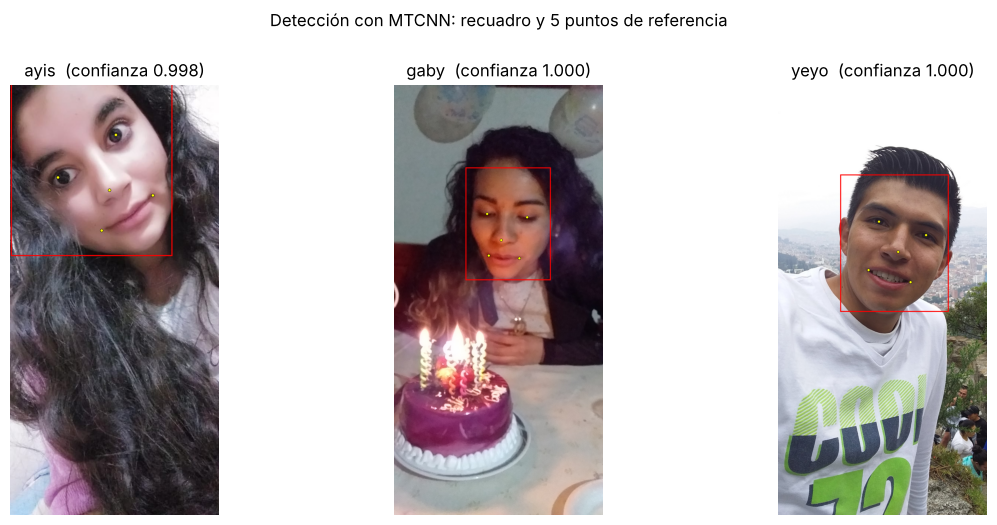

In [3]:
# Lo que ve el detector: recuadro y los 5 puntos, en una foto de cada persona
from PIL import ImageDraw
personas = sorted(fotos.persona.unique())
fig, ejes = plt.subplots(1, len(personas), figsize=(4.2 * len(personas), 5.2))
for eje, p in zip(np.atleast_1d(ejes), personas):
    clave = next(k for k in detecciones if k.startswith(p + "/") and k not in EXCLUIR and detecciones[k][1] is not None)
    im, (caja, prob, pts, n) = detecciones[clave][0].copy(), detecciones[clave][1]
    d = ImageDraw.Draw(im)
    d.rectangle(list(caja), outline="red", width=max(3, im.size[0] // 200))
    for x, y in pts:
        r = max(4, im.size[0] // 160)
        d.ellipse([x - r, y - r, x + r, y + r], fill="yellow", outline="black")
    eje.imshow(im); eje.set_title(f"{p}  (confianza {prob:.3f})"); eje.axis("off")
plt.suptitle("Detección con MTCNN: recuadro y 5 puntos de referencia", y=1.0)
plt.tight_layout(); plt.show()

**Lectura.** MTCNN encontró cara en **las 42 fotos** (ninguna sin detección), con una confianza mediana de 0.9999 y un rostro de 252 píxeles de lado
en promedio (mediana). Pero **7 fotos tienen más de una cara** (de grupo o con otras personas al fondo): ahí la regla "la cara más grande" funciona
en la mayoría de los casos, aunque no es infalible. En dos fotos de grupo de gaby no se puede saber con certeza cuál de las tres personas es ella, por lo que se excluyeron.
Los rostros más pequeños miden 74 px (ayis), 40 px (gaby) y 34 px (yeyo): estos últimos son recortes ampliados de muy baja calidad.

## 3. Alineación y recorte

Dos fotos de la misma persona pueden tener la cabeza inclinada de forma distinta. Para que la red no tenga que
aprender también eso, se **alinea** cada rostro: con la posición de los dos ojos se calcula el ángulo de la línea que
los une y se rota la imagen alrededor del centro del rostro para dejarla horizontal. Después se recorta un cuadrado
con el **30 % de margen** (para conservar frente y barbilla) y se redimensiona a 112 × 112 píxeles.

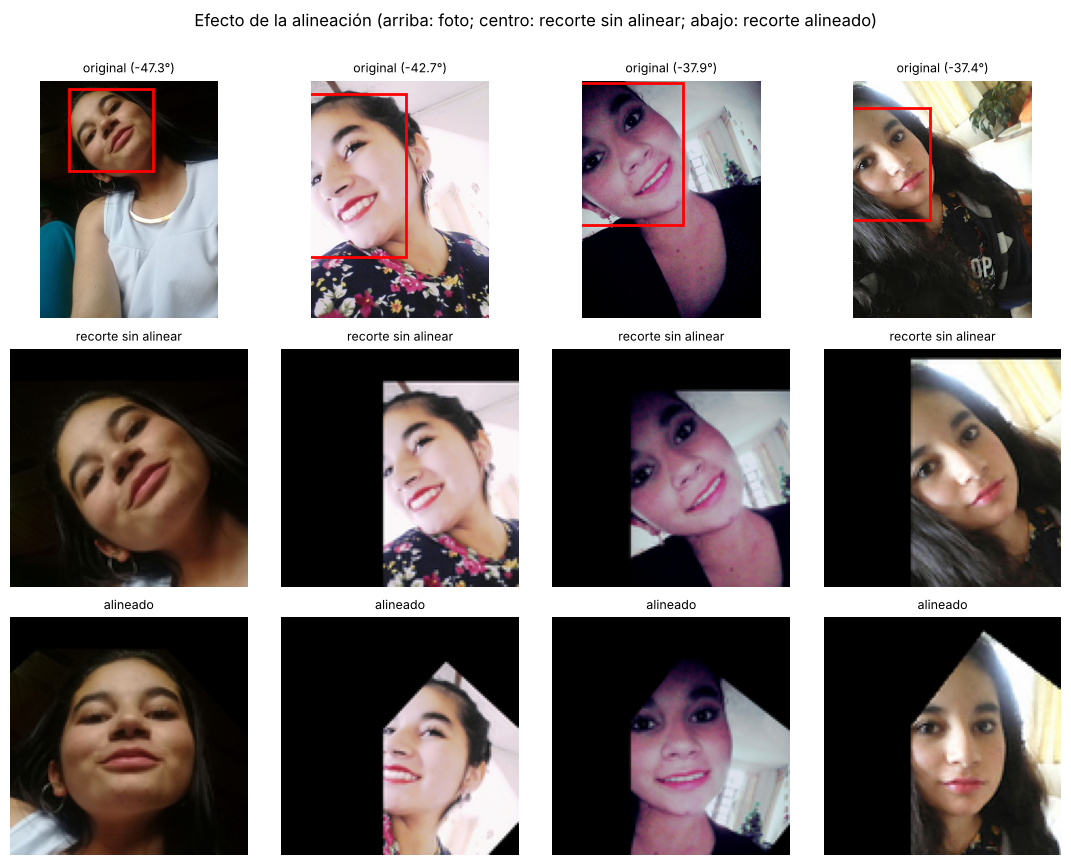

Inclinación de la línea de los ojos (grados): mediana |ángulo| = 15.5 | máxima = 47.3 | fotos con más de 5° = 26 de 39


In [4]:
def alinear_y_recortar(im, caja, puntos, tam=TAM, margen=MARGEN):
    ojo_i, ojo_d = puntos[0], puntos[1]
    angulo = math.degrees(math.atan2(ojo_d[1] - ojo_i[1], ojo_d[0] - ojo_i[0]))   # inclinación de la línea de los ojos
    cx, cy = (caja[0] + caja[2]) / 2, (caja[1] + caja[3]) / 2
    girada = im.rotate(angulo, resample=Image.BICUBIC, center=(cx, cy), fillcolor=(0, 0, 0))
    lado = max(caja[2] - caja[0], caja[3] - caja[1]) * (1 + 2 * margen)
    recorte = girada.crop((cx - lado / 2, cy - lado / 2, cx + lado / 2, cy + lado / 2))
    return recorte.resize((tam, tam), Image.LANCZOS), angulo

def sin_alinear(im, caja, tam=TAM, margen=MARGEN):
    cx, cy = (caja[0] + caja[2]) / 2, (caja[1] + caja[3]) / 2
    lado = max(caja[2] - caja[0], caja[3] - caja[1]) * (1 + 2 * margen)
    return im.crop((cx - lado / 2, cy - lado / 2, cx + lado / 2, cy + lado / 2)).resize((tam, tam), Image.LANCZOS)

# Efecto de la alineación en las 4 fotos con mayor inclinación
inclinaciones = {}
for clave, (im, d) in detecciones.items():
    if d is not None and clave not in EXCLUIR:
        _, ang = alinear_y_recortar(im, d[0], d[2])
        inclinaciones[clave] = ang
top = sorted(inclinaciones, key=lambda k: -abs(inclinaciones[k]))[:4]

fig, ejes = plt.subplots(3, 4, figsize=(11, 8.6))
for j, clave in enumerate(top):
    im, (caja, prob, pts, n) = detecciones[clave]
    ejes[0, j].imshow(im); ejes[0, j].add_patch(plt.Rectangle((caja[0], caja[1]), caja[2] - caja[0], caja[3] - caja[1], fill=False, ec="red", lw=2))
    ejes[0, j].set_title(f"original ({inclinaciones[clave]:+.1f}°)", fontsize=9)
    ejes[1, j].imshow(sin_alinear(im, caja)); ejes[1, j].set_title("recorte sin alinear", fontsize=9)
    ejes[2, j].imshow(alinear_y_recortar(im, caja, pts)[0]); ejes[2, j].set_title("alineado", fontsize=9)
for e in ejes.ravel():
    e.axis("off")
plt.suptitle("Efecto de la alineación (arriba: foto; centro: recorte sin alinear; abajo: recorte alineado)", y=1.0)
plt.tight_layout(); plt.show()

angulos = pd.Series(inclinaciones)
print("Inclinación de la línea de los ojos (grados): mediana |ángulo| =", round(float(angulos.abs().median()), 1),
      "| máxima =", round(float(angulos.abs().max()), 1), "| fotos con más de 5° =", int((angulos.abs() > 5).sum()), "de", len(angulos))

**Lectura.** La línea de los ojos está inclinada en la mayoría de las fotos: en **26 de las 39 fotos** el ángulo supera los 5°, con una mediana de
15.5° y un máximo de 47.3° (selfies con el celular inclinado). Sin alinear, la red tendría que aprender a reconocer la misma cara rotada de muchas
maneras con muy pocos ejemplos; con la alineación, los ojos quedan siempre en la misma altura y la cara ocupa la misma posición del recorte. Las zonas
negras en algunos recortes son el relleno que aparece al rotar y recortar cerca del borde de la foto original; son inevitables y es una limitación conocida de esta forma de alinear.

## 4. Dataset final y control de calidad

Se aplican las reglas (confianza, tamaño mínimo y exclusiones), se guardan los recortes en
`datos/rostros/<persona>/` y se calculan tres medidas de calidad de cada uno:

- **Lado del rostro** en la foto original: si es pequeño, el recorte es una imagen ampliada y borrosa.
- **Nitidez** (varianza del laplaciano): valores bajos indican imagen desenfocada.
- **Brillo** medio (0 a 255): detecta fotos muy oscuras o muy claras.

In [5]:
import cv2
os.makedirs(CARPETA_ROSTROS, exist_ok=True)

registros = []
descartadas = []
contador = {}
for clave, (im, d) in detecciones.items():
    persona, archivo = clave.split("/")
    if clave in EXCLUIR:
        descartadas.append({"foto": clave, "motivo": EXCLUIR[clave]}); continue
    if d is None:
        descartadas.append({"foto": clave, "motivo": "no se detectó cara"}); continue
    caja, prob, pts, n = d
    lado = min(caja[2] - caja[0], caja[3] - caja[1])
    if prob < PROB_MIN or lado < LADO_MIN:
        descartadas.append({"foto": clave, "motivo": f"confianza {prob:.2f} / lado {lado:.0f}px"}); continue
    recorte, ang = alinear_y_recortar(im, caja, pts)
    contador[persona] = contador.get(persona, 0) + 1
    nombre = f"{persona}_{contador[persona]:02d}.png"
    os.makedirs(f"{CARPETA_ROSTROS}/{persona}", exist_ok=True)
    recorte.save(f"{CARPETA_ROSTROS}/{persona}/{nombre}")
    gris = cv2.cvtColor(np.array(recorte), cv2.COLOR_RGB2GRAY)
    registros.append({"persona": persona, "archivo": nombre, "foto_original": archivo, "caras_en_foto": n, "confianza": prob,
                      "lado_rostro_px": lado, "inclinacion_grados": ang,
                      "nitidez": float(cv2.Laplacian(gris, cv2.CV_64F).var()), "brillo": float(gris.mean())})

meta = pd.DataFrame(registros)
meta.to_csv("datos/metadatos.csv", index=False)
print(f"Rostros guardados: {len(meta)}   |   fotos descartadas: {len(descartadas)}")
for d in descartadas:
    print("  descartada:", d["foto"], "->", d["motivo"])
print()
print(meta.groupby("persona").agg(rostros=("archivo", "count"), lado_mediano=("lado_rostro_px", "median"),
                                  nitidez_mediana=("nitidez", "median"), brillo_medio=("brillo", "mean")).round(1).to_string())

Rostros guardados: 38   |   fotos descartadas: 4
  descartada: gaby/20260101_152019.jpg -> foto de grupo con 3 personas de tamaño parecido
  descartada: gaby/20260501_151237.jpg -> foto de grupo con 3 personas de tamaño parecido
  descartada: yeyo/20250812_075818.jpg -> confianza 0.99 / lado 34px
  descartada: yeyo/Screenshot_20221031-220205_WhatsApp.jpg -> captura de pantalla cuyo rostro principal es de otra persona (se vio al revisar los recortes)

         rostros  lado_mediano  nitidez_mediana  brillo_medio
persona                                                      
ayis          17         424.8           1103.4          80.6
gaby           7         253.1            770.7          89.3
yeyo          14         233.3           1370.2         111.2


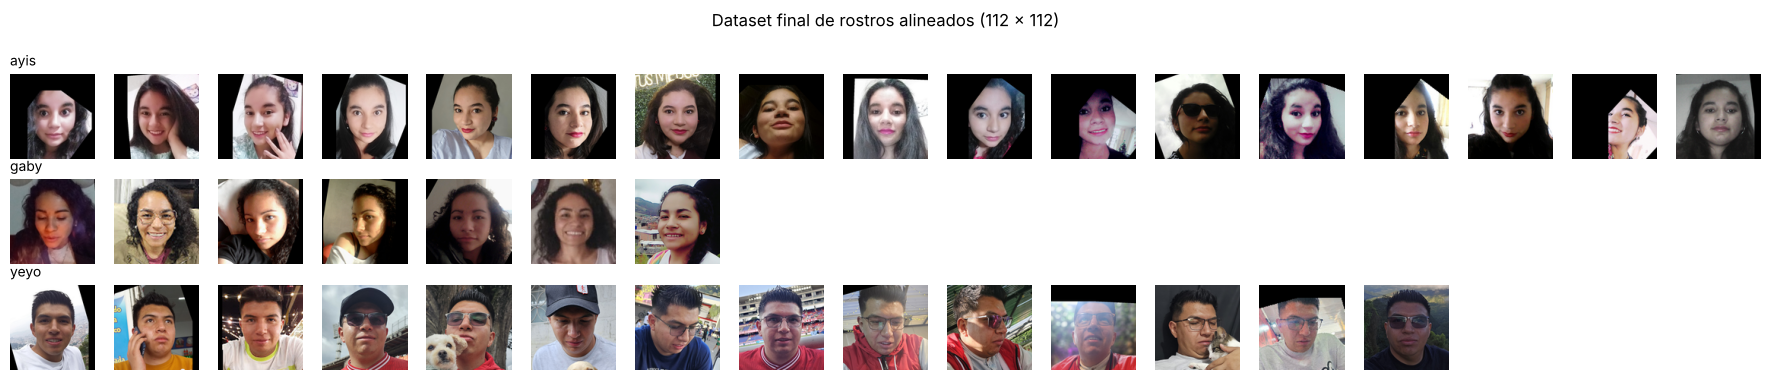

In [6]:
# Todos los rostros del dataset, una fila por persona
personas = sorted(meta.persona.unique())
mayor = int(meta.groupby("persona").size().max())
fig, ejes = plt.subplots(len(personas), mayor, figsize=(mayor * 1.05, len(personas) * 1.25))
for i, p in enumerate(personas):
    archivos = meta[meta.persona == p].archivo.tolist()
    for j in range(mayor):
        ejes[i, j].axis("off")
        if j < len(archivos):
            ejes[i, j].imshow(Image.open(f"{CARPETA_ROSTROS}/{p}/{archivos[j]}"))
    ejes[i, 0].set_title(p, loc="left", fontsize=10)
plt.suptitle("Dataset final de rostros alineados (112 × 112)", y=1.0)
plt.tight_layout(); plt.show()

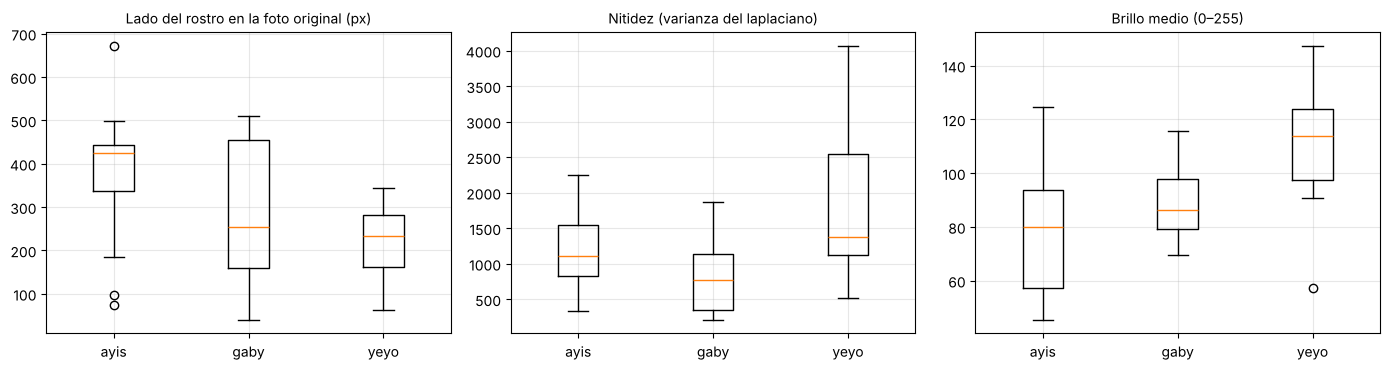

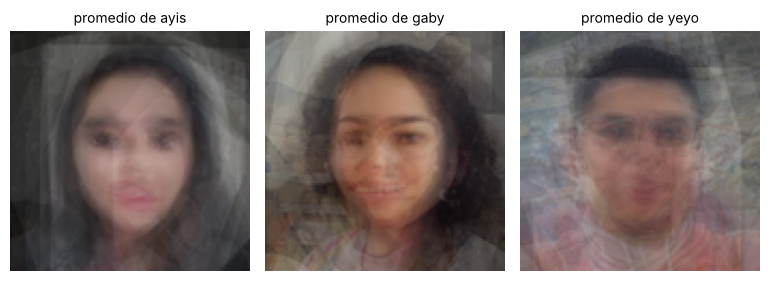

Rostros pequeños (lado < 80 px): 5 de 38
Rostros poco nítidos (nitidez < 100): 0 de 38


In [7]:
# Calidad: tamaño del rostro, nitidez y brillo por persona
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
for eje, col, titulo in zip(ejes, ["lado_rostro_px", "nitidez", "brillo"],
                            ["Lado del rostro en la foto original (px)", "Nitidez (varianza del laplaciano)", "Brillo medio (0–255)"]):
    datos = [meta[meta.persona == p][col].values for p in personas]
    eje.boxplot(datos); eje.set_xticks(range(1, len(personas) + 1)); eje.set_xticklabels(personas); eje.set_title(titulo, fontsize=10); eje.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Rostro promedio de cada persona (muestra qué parte de la cara es estable entre fotos)
fig, ejes = plt.subplots(1, len(personas), figsize=(2.6 * len(personas), 2.9))
for eje, p in zip(ejes, personas):
    pila = np.stack([np.array(Image.open(f"{CARPETA_ROSTROS}/{p}/{a}")) for a in meta[meta.persona == p].archivo]).astype(float)
    eje.imshow(pila.mean(axis=0).astype("uint8")); eje.set_title(f"promedio de {p}", fontsize=10); eje.axis("off")
plt.tight_layout(); plt.show()

print("Rostros pequeños (lado < 80 px):", int((meta.lado_rostro_px < 80).sum()), "de", len(meta))
print("Rostros poco nítidos (nitidez < 100):", int((meta.nitidez < 100).sum()), "de", len(meta))

**Lectura del dataset final.** Quedan **38 rostros alineados de 112 × 112 píxeles**: ayis 17, gaby 7 y yeyo 14. Se descartaron 4 fotos: dos fotos de grupo de gaby, una foto de yeyo
con un rostro de apenas 34 píxeles, y una **captura de pantalla en la que el rostro principal era de otra persona**. Ese último caso lo detectó
la revisión visual de los recortes, no el detector: MTCNN solo dice *dónde hay una cara*, no *de quién es*. Es una lección práctica: **la calidad del dataset facial exige revisar las imágenes**,
porque una sola foto mal etiquetada contamina la identidad completa.

En calidad: 5 de los 38 rostros son pequeños (lado menor a 80 px, es decir, ampliados) y ninguno está desenfocado según el umbral usado (nitidez > 100). La nitidez mediana
es de 1 103 (ayis), 771 (gaby) y 1 370 (yeyo), y el brillo medio de 81, 89 y 111 sobre 255: las fotos de ayis son en promedio las más oscuras.

### Resumen de las decisiones de preprocesamiento

| Decisión | Por qué |
|---|---|
| Detección con MTCNN, cara más grande | Quedarse solo con la persona principal de la foto. |
| Alineación por la línea de los ojos | Que todas las caras tengan la misma orientación. |
| Margen del 30 % y recorte cuadrado de 112 × 112 | Conservar frente y barbilla, y tener un tamaño de entrada uniforme. |
| Descartar fotos de grupo ambiguas y capturas con otra persona | No mezclar identidades: una foto mal etiquetada daña toda una identidad. |
| Carpetas por persona y `metadatos.csv` | Dataset organizado y trazable (foto original, confianza, tamaño, nitidez, brillo). |
| Normalización de píxeles y aumento de datos en el entrenamiento (Partes 2 y 3) | Evitar que la red memorice las pocas fotos disponibles. |

---
## Referencias

- Hermans, A., Beyer, L., y Leibe, B. (2017). *In defense of the triplet loss for person re-identification*. arXiv:1703.07737.
- Koch, G., Zemel, R., y Salakhutdinov, R. (2015). Siamese neural networks for one-shot image recognition. *ICML Deep Learning Workshop*.
- Schroff, F., Kalenichenko, D., y Philbin, J. (2015). FaceNet: A unified embedding for face recognition and clustering. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 815–823.
- Zhang, K., Zhang, Z., Li, Z., y Qiao, Y. (2016). Joint face detection and alignment using multitask cascaded convolutional networks. *IEEE Signal Processing Letters, 23*(10), 1499–1503.
- Documentación de PyTorch (pytorch.org), TensorFlow / Keras (keras.io) y scikit-learn (scikit-learn.org).